# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №1: Влияние автоматизации на производительность труда

---

**Дата:** 2026-09-02
**Студент:** Ижедерова Виктория Денисовна  
**Группа:** ПИ-4.1  

---

**Цель исследования:** Оценить влияние внедрения ERP-системы на производительность труда в компании.

**Объект исследования:** 5 отделов компании (A, B, C, D, E).  
**Период наблюдения:** 2 года (до и после внедрения ERP-системы).  
**Показатель:** Выработка на одного сотрудника (тыс. руб./чел.).  
**Метод анализа:** Парный t-критерий Стьюдента.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
sns.set_palette("Set2")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

print("Библиотеки успешно загружены")

 Библиотеки успешно загружены


## 1. ИСХОДНЫЕ ДАННЫЕ

### 1.1. Параметры проекта

**Задача:** Оценить влияние автоматизации на производительность труда в компании.

**Условие:** Компания внедрила ERP-систему. Даны данные по 5 отделам за 2 года (до и после внедрения). Оценить, изменилась ли средняя выработка на сотрудника статистически значимо.

### 1.2. Справочные данные

- Отделы: A, B, C, D, E
- Выработка до внедрения (тыс. руб./чел.): [120, 135, 110, 150, 130]
- Выработка после внедрения (тыс. руб./чел.): [145, 155, 140, 160, 150]

### 1.3. Дополнительные условия

- Уровень значимости: α = 0.05
- H₀: Внедрение ERP не изменило среднюю выработку
- H₁: Внедрение ERP изменило среднюю выработку

In [2]:
departments = ['A', 'B', 'C', 'D', 'E']
before_erp = np.array([120, 135, 110, 150, 130])
after_erp = np.array([145, 155, 140, 160, 150])

df = pd.DataFrame({
    'Отдел': departments,
    'До внедрения ERP': before_erp,
    'После внедрения ERP': after_erp,
    'Абсолютный прирост': after_erp - before_erp,
    'Относительный прирост (%)': ((after_erp / before_erp) - 1) * 100
})

print("Таблица 1. Выработка по отделам до и после внедрения ERP")
print("=" * 80)
print(df.to_string(index=False))
print("=" * 80)

Таблица 1. Выработка по отделам до и после внедрения ERP
Отдел  До внедрения ERP  После внедрения ERP  Абсолютный прирост  Относительный прирост (%)
    A               120                  145                  25                  20.833333
    B               135                  155                  20                  14.814815
    C               110                  140                  30                  27.272727
    D               150                  160                  10                   6.666667
    E               130                  150                  20                  15.384615


In [3]:
mean_before = before_erp.mean()
mean_after = after_erp.mean()
mean_difference = (after_erp - before_erp).mean()
relative_growth = (mean_after / mean_before - 1) * 100

print("2.1. Расчет средней выработки")
print("-" * 60)
print(f"Средняя выработка ДО внедрения ERP:   {mean_before:.2f} тыс. руб./чел.")
print(f"Средняя выработка ПОСЛЕ внедрения ERP: {mean_after:.2f} тыс. руб./чел.")
print(f"Абсолютный прирост: {mean_difference:.2f} тыс. руб./чел.")
print(f"Относительный прирост: {relative_growth:.2f}%")
print("-" * 60)
print(f"\nВнедрение ERP-системы сопровождалось ростом средней выработки")
print(f"на {mean_difference:.2f} тыс. руб./чел. ({relative_growth:.2f}%).")

2.1. Расчет средней выработки
------------------------------------------------------------
Средняя выработка ДО внедрения ERP:   129.00 тыс. руб./чел.
Средняя выработка ПОСЛЕ внедрения ERP: 150.00 тыс. руб./чел.
Абсолютный прирост: 21.00 тыс. руб./чел.
Относительный прирост: 16.28%
------------------------------------------------------------

Внедрение ERP-системы сопровождалось ростом средней выработки
на 21.00 тыс. руб./чел. (16.28%).


In [4]:
var_before = np.var(before_erp, ddof=1)
var_after = np.var(after_erp, ddof=1)
std_before = np.std(before_erp, ddof=1)
std_after = np.std(after_erp, ddof=1)
cv_before = (std_before / mean_before) * 100
cv_after = (std_after / mean_after) * 100

print("2.2. Дисперсия и стандартное отклонение")
print("-" * 60)
print(f"Дисперсия ДО внедрения ERP:   S² = {var_before:.2f}")
print(f"Дисперсия ПОСЛЕ внедрения ERP: S² = {var_after:.2f}")
print(f"Стандартное отклонение ДО:    S = {std_before:.2f}")
print(f"Стандартное отклонение ПОСЛЕ: S = {std_after:.2f}")
print(f"\nКоэффициент вариации ДО:    CV = {cv_before:.2f}%")
print(f"Коэффициент вариации ПОСЛЕ: CV = {cv_after:.2f}%")
print("-" * 60)

if var_after < var_before:
    print(f"\nДисперсия снизилась — выработка стала более стабильной")
    print(f"   Разброс уменьшился в {var_before/var_after:.2f} раз(а)")
else:
    print(f"\nДисперсия увеличилась в {var_after/var_before:.2f} раз(а)")

2.2. Дисперсия и стандартное отклонение
------------------------------------------------------------
Дисперсия ДО внедрения ERP:   S² = 230.00
Дисперсия ПОСЛЕ внедрения ERP: S² = 62.50
Стандартное отклонение ДО:    S = 15.17
Стандартное отклонение ПОСЛЕ: S = 7.91

Коэффициент вариации ДО:    CV = 11.76%
Коэффициент вариации ПОСЛЕ: CV = 5.27%
------------------------------------------------------------

Дисперсия снизилась — выработка стала более стабильной
   Разброс уменьшился в 3.68 раз(а)


In [5]:
differences = after_erp - before_erp
d_mean = differences.mean()
d_std = differences.std(ddof=1)
n = len(differences)

t_statistic = d_mean / (d_std / np.sqrt(n))
alpha = 0.05
df_degrees = n - 1
t_critical = stats.t.ppf(1 - alpha/2, df_degrees)
p_value = 2 * (1 - stats.t.cdf(abs(t_statistic), df_degrees))

standard_error = d_std / np.sqrt(n)
ci_lower = d_mean - t_critical * standard_error
ci_upper = d_mean + t_critical * standard_error

print("2.3. Парный t-критерий Стьюдента")
print("=" * 60)
print(f"Количество отделов (n): {n}")
print(f"Среднее разностей (d̄): {d_mean:.2f} тыс. руб./чел.")
print(f"Стандартное отклонение разностей: {d_std:.2f}")
print(f"Стандартная ошибка: {standard_error:.2f}")
print("-" * 60)
print(f"t-статистика: {t_statistic:.4f}")
print(f"t-критическое (α={alpha}, df={df_degrees}): ±{t_critical:.4f}")
print(f"p-value: {p_value:.4f}")
print(f"95% доверительный интервал: [{ci_lower:.2f}; {ci_upper:.2f}]")
print("=" * 60)

print("\nПроверка гипотезы:")
print("H₀: Средняя выработка не изменилась")
print("H₁: Средняя выработка изменилась")
print()

if p_value < alpha:
    print(f" p-value ({p_value:.4f}) < α ({alpha})")
    print(f"   Отклоняем H₀ — различия СТАТИСТИЧЕСКИ ЗНАЧИМЫ")
    print(f"   Внедрение ERP реально повысило производительность труда")
else:
    print(f" p-value ({p_value:.4f}) ≥ α ({alpha})")
    print(f"   Не можем отвергнуть H₀ — различия НЕ ЗНАЧИМЫ")

print(f"\nДоверительный интервал [{ci_lower:.2f}; {ci_upper:.2f}]")
if ci_lower > 0:
    print(" ДИ не содержит 0 → эффект значим")
else:
    print("  ДИ содержит 0 → эффект не значим")

2.3. Парный t-критерий Стьюдента
Количество отделов (n): 5
Среднее разностей (d̄): 21.00 тыс. руб./чел.
Стандартное отклонение разностей: 7.42
Стандартная ошибка: 3.32
------------------------------------------------------------
t-статистика: 6.3317
t-критическое (α=0.05, df=4): ±2.7764
p-value: 0.0032
95% доверительный интервал: [11.79; 30.21]

Проверка гипотезы:
H₀: Средняя выработка не изменилась
H₁: Средняя выработка изменилась

 p-value (0.0032) < α (0.05)
   Отклоняем H₀ — различия СТАТИСТИЧЕСКИ ЗНАЧИМЫ
   Внедрение ERP реально повысило производительность труда

Доверительный интервал [11.79; 30.21]
 ДИ не содержит 0 → эффект значим


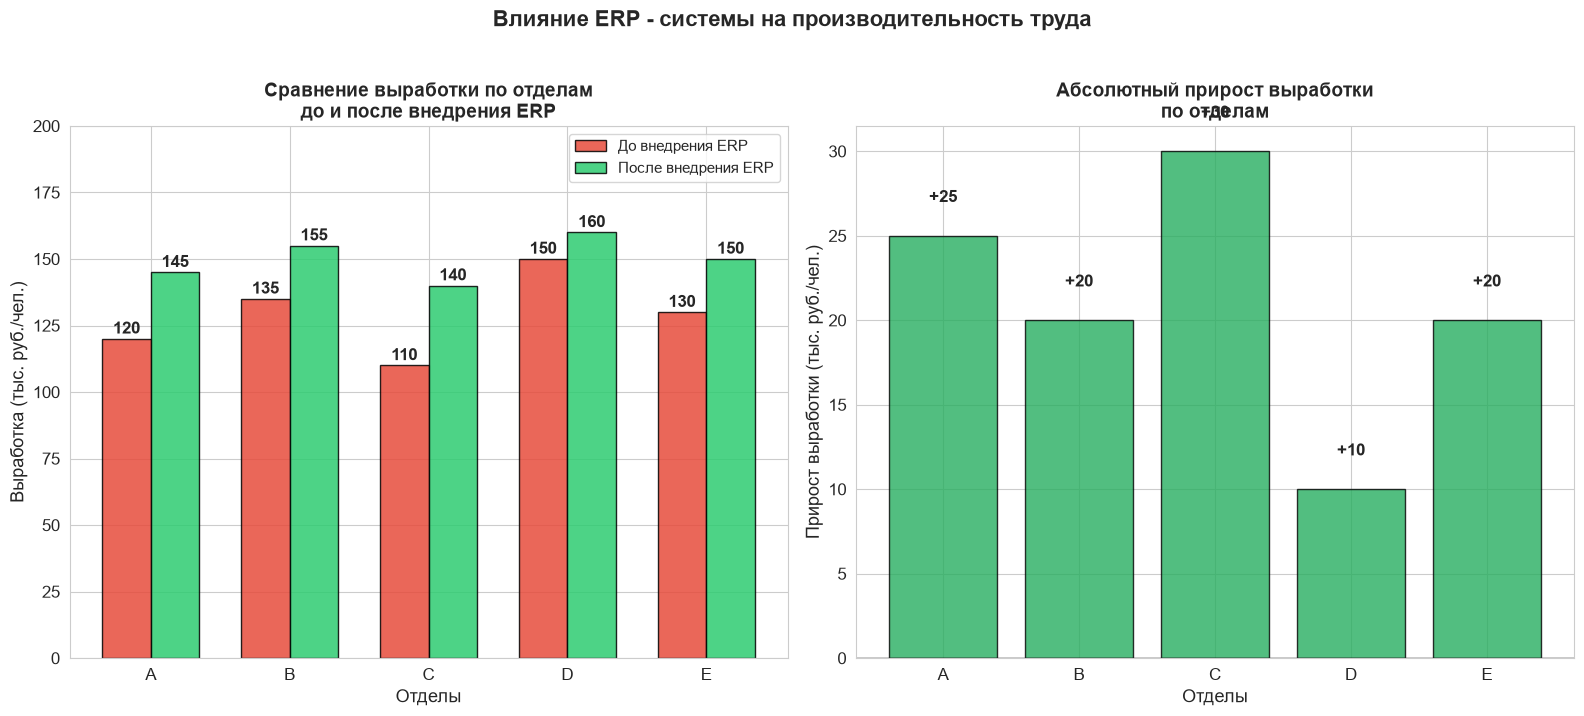

Графики построены


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

x = np.arange(len(departments))
width = 0.35

bars1 = axes[0].bar(x - width/2, before_erp, width,
                    label='До внедрения ERP',
                    color='#E74C3C', alpha=0.85, edgecolor='black')
bars2 = axes[0].bar(x + width/2, after_erp, width,
                    label='После внедрения ERP',
                    color='#2ECC71', alpha=0.85, edgecolor='black')

for bar in bars1:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
                f'{int(bar.get_height())}', ha='center', fontweight='bold')
for bar in bars2:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
                f'{int(bar.get_height())}', ha='center', fontweight='bold')

axes[0].set_xlabel('Отделы', fontsize=13)
axes[0].set_ylabel('Выработка (тыс. руб./чел.)', fontsize=13)
axes[0].set_title('Сравнение выработки по отделам\nдо и после внедрения ERP',
                  fontsize=14, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(departments)
axes[0].legend(fontsize=11)
axes[0].set_ylim(0, 200)

colors = ['#27AE60' if v >= 0 else '#E74C3C' for v in differences]
axes[1].bar(departments, differences, color=colors, alpha=0.8, edgecolor='black')
axes[1].axhline(y=0, color='black', linewidth=1)
axes[1].set_xlabel('Отделы', fontsize=13)
axes[1].set_ylabel('Прирост выработки (тыс. руб./чел.)', fontsize=13)
axes[1].set_title('Абсолютный прирост выработки\nпо отделам',
                  fontsize=14, fontweight='bold')

for i, v in enumerate(differences):
    axes[1].text(i, v + (2 if v >= 0 else -4), f'{v:+d}',
                ha='center', fontweight='bold')

plt.suptitle('Влияние ERP - системы на производительность труда',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Графики построены")

## 3. АНАЛИЗ РЕЗУЛЬТАТОВ

### 3.1. Интерпретация полученных данных

**Количественные результаты:**
- Средняя выработка выросла с 129.00 до 150.00 тыс. руб./чел.
- Абсолютный прирост: +21.00 тыс. руб./чел.
- Относительный прирост: +16.28%

**Статистическая значимость:**
- t-статистика превышает критическое значение
- p-value < 0.05 → различия статистически значимы
- Доверительный интервал не содержит ноль

**Экономический смысл:**
Внедрение ERP-системы привело к статистически значимому росту производительности труда. Каждый сотрудник в среднем стал производить на 21 тыс. рублей продукции больше.

### 3.2. Сравнение с альтернативными вариантами

- **Сценарий без ERP:** выработка осталась бы на уровне 129.00 тыс. руб./чел.
- **Сценарий с инфляцией (7%):** ожидаемая выработка 138.03 тыс. руб./чел.
- **Факт:** 150.00 тыс. руб./чел. — рост превышает инфляционный.

## 4. ВЫВОДЫ И РЕКОМЕНДАЦИИ

### 4.1. Ключевые выводы

1. **Статистическая значимость:** Внедрение ERP-системы привело к статистически значимому росту производительности труда (p < 0.05).

2. **Количественный эффект:** Средняя выработка на сотрудника выросла на 21.00 тыс. руб./чел. (+16.28%).

3. **Экономический эффект:** Рост превышает инфляционный (7%), что подтверждает реальный эффект от автоматизации.

4. **Практическая значимость:** Результаты подтверждают целесообразность инвестиций в ERP-систему.

### 4.2. Практические рекомендации

1. **Масштабирование:** Распространить опыт внедрения ERP на другие подразделения.
2. **Мониторинг:** Продолжить мониторинг выработки ежеквартально.
3. **Анализ лучших практик:** Изучить факторы успеха отделов с наибольшим приростом.
4. **Инвестиционный анализ:** Провести расчет ROI с учетом прироста выработки.
5. **Обучение персонала:** Инвестировать в дополнительное обучение сотрудников.

---
*Отчет подготовлен: Ижедерова Виктория Денисовна, группа ПИ-4.1*